<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Measure ingestion without hiding coverage gaps

**Which tables dominate measured ingestion, and which have no usable observations?**
Send a visible KQL projection through the worker, type its JSON rows in SQL, and
join them to the worker's curated table index. Compare daily volumes and table
totals while keeping measured zero, missing quantity, unsupported units and
absent observations distinct.

**Synthetic local HTTP data, real worker.** Every observation and June 2026
timestamp is invented. The unchanged remote function builds the query request,
decodes a Kusto `tables/columns/rows` envelope and emits its real Arrow schema.
Its existing client-factory seam points to loopback. The fixture supports this
exact projection; it is **not a KQL interpreter or an Azure workspace**.
No real credentials, paid queries, remote writes or tenant data are used.

## Choose a fixed UTC window

`WINDOW_DAYS` is an integer from **1 through 7**. The window ends at
**25 June 2026, 00:00 UTC (exclusive)** and starts that many days earlier
(inclusive). The default is **7 days**; the experiment uses **3 days**.
Restart and run all after editing.

The synthetic `QuantityUnit = 'MBytes'` values use **decimal MB**:
1 MB = 1,000,000 bytes and 1 GB = 1,000 MB. We report observed ingestion quantities,
not a bill or price estimate. Missing or incompatible measurements are excluded
from sums and counted explicitly; a measured zero remains zero.

In [1]:
WINDOW_DAYS = 7  # integer 1–7; fixed end 2026-06-25 00:00 UTC, exclusive

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))
os.chdir(NOTEBOOK_DIR)
import haybarn
import matplotlib.pyplot as plt
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme
from synthetic_loganalytics_api import QUERY

fixture, previous_url, start_iso, end_iso = configure(WINDOW_DAYS)
timespan = start_iso + "/" + end_iso
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-azure-loganalytics-portable-mgtm0sjx/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-azure-loganalytics-portable-mgtm0sjx/pyproject.toml.

## Connect the release and the fixture transport

Native **v0.4.0** supplies credential-free table discovery. The fixture connection
uses a Bun/Git launcher pinned to public revision
**`9b7c851b11599935a5acedcebd77180c82092548`**. It installs that revision's frozen
lock and registers its unchanged query function and catalog. Only the injected
HTTP client is replaced. Git, Bun and first-run downloads are required; no parent
worker checkout is needed.

The secret contains public dummy strings and satisfies the function's lookup.
It performs no Microsoft Entra authentication. The index is curated documentation,
**not an enumeration of tables installed or enabled in a workspace**.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'azure' AS azure_release (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-azure-loganalytics@v0.4.0');
-- Remote source 9b7c851b11599935a5acedcebd77180c82092548, using its frozen Bun lock.
ATTACH 'azure' AS azure_fixture (TYPE vgi, LOCATION 'bash launch_fixture.sh');
CREATE SECRET notebook_fixture (TYPE azure_graph,
    TENANT_ID '00000000-0000-0000-0000-000000000001',
    CLIENT_ID '00000000-0000-0000-0000-000000000002',
    CLIENT_SECRET 'synthetic-not-a-credential');
CREATE TABLE table_index AS
SELECT table_name, category FROM azure_release.main.loganalytics_tables WHERE table_name <> 'Usage';
SELECT * FROM table_index ORDER BY category, table_name;

,table_name,category
0,AADNonInteractiveUserSignInLogs,identity
1,AuditLogs,identity
2,SigninLogs,identity
3,Heartbeat,infrastructure
4,AzureActivity,platform
5,AzureDiagnostics,platform


In [4]:
prose(
    f"**Synthetic HTTP fixture:** `{fixture.url}`. Query window: **{start_iso} ≤ timestamp < {end_iso}**. "
    "`Usage` is excluded from the index comparison because it is the measurement source itself."
)

**Synthetic HTTP fixture:** `http://127.0.0.1:65202`. Query window: **2026-06-18T00:00:00Z ≤ timestamp < 2026-06-25T00:00:00Z**. `Usage` is excluded from the index comparison because it is the measurement source itself.

## Materialize one query, then inspect its JSON

The KQL is a literal projection sent verbatim. The fixture applies the explicit
half-open UTC interval and returns a deterministic envelope. No `since` cursor is
used: this is a snapshot query and should have no marker row. Materialize the
worker result once so subsequent captures and charts cannot repeat the HTTP POST.

In [5]:
%%sql
CREATE TABLE raw_usage AS
SELECT * FROM azure_fixture.main.loganalytics_query(
    'Usage | project TimeGenerated, DataType, Quantity, QuantityUnit',
    '11111111-2222-3333-4444-555555555555',
    timespan := '{{timespan}}');
SELECT result FROM raw_usage ORDER BY result LIMIT 4;

,result
0,"{""TimeGenerated"":""2026-06-18T12:00:00Z"",""DataT..."
1,"{""TimeGenerated"":""2026-06-18T12:00:00Z"",""DataT..."
2,"{""TimeGenerated"":""2026-06-18T12:00:00Z"",""DataT..."
3,"{""TimeGenerated"":""2026-06-18T12:00:00Z"",""DataT..."


## Type the projection and make exclusions visible

A fixed `result` string schema can carry different KQL projections. SQL must
extract the requested fields, parse timestamps and numbers, and validate units.
Only finite, nonnegative quantities with the expected unit enter the MB totals.
Missing quantity and incompatible units receive separate reasons. The raw JSON
stays available for inspection; excluded rows are not replaced with zeros.

In [6]:
%%sql
CREATE TABLE typed_usage AS
WITH parsed AS (
  SELECT result,
         try_cast(json_extract_string(result,'$.TimeGenerated') AS TIMESTAMPTZ) AS observed_at,
         json_extract_string(result,'$.DataType') AS table_name,
         try_cast(json_extract_string(result,'$.Quantity') AS DOUBLE) AS quantity_mb,
         json_extract_string(result,'$.QuantityUnit') AS unit
  FROM raw_usage WHERE _row_kind IS NULL
)
SELECT *, CASE
  WHEN observed_at IS NULL OR table_name IS NULL OR table_name = '' THEN 'invalid key/time'
  WHEN unit IS DISTINCT FROM 'MBytes' THEN 'unsupported unit'
  WHEN quantity_mb IS NULL THEN 'missing or invalid quantity'
  WHEN NOT isfinite(quantity_mb) OR quantity_mb < 0 THEN 'invalid quantity range'
  ELSE 'usable' END AS measurement_status
FROM parsed;
SELECT measurement_status, count(*) AS rows,
       count(*) FILTER (WHERE quantity_mb = 0) AS measured_zeros
FROM typed_usage GROUP BY measurement_status ORDER BY measurement_status;

,measurement_status,rows,measured_zeros
0,missing or invalid quantity,1,0
1,unsupported unit,1,0
2,usable,42,7


In [7]:
%%sql exclusions <<
SELECT observed_at, table_name, quantity_mb, unit, measurement_status
FROM typed_usage WHERE measurement_status <> 'usable' ORDER BY observed_at, table_name;

In [8]:
display(exclusions)

,observed_at,table_name,quantity_mb,unit,measurement_status
0,2026-06-22 14:00:00-04:00,AzureDiagnostics,NaN,MBytes,missing or invalid quantity
1,2026-06-23 14:00:00-04:00,Unmapped_CL,5.0,packets,unsupported unit


## Join observations to the curated table index

A full join retains custom tables absent from the index as **Unlisted**. Conversely,
an indexed table with no rows is **not observed** in this response; that does not
prove an outage, disabled collection or zero ingestion. A table with only excluded
measurements has a different status: **no usable quantity**. Even a table with a
known subtotal may have excluded observations, so the subtotal is not its complete
volume when coverage is partial.

In [9]:
%%sql
CREATE TABLE table_coverage AS
WITH observed AS (
  SELECT table_name, count(*) AS observed_rows,
         count(*) FILTER (WHERE measurement_status = 'usable') AS usable_rows,
         count(*) FILTER (WHERE measurement_status <> 'usable') AS excluded_rows,
         sum(quantity_mb) FILTER (WHERE measurement_status = 'usable') AS known_mb
  FROM typed_usage GROUP BY table_name
)
SELECT coalesce(i.table_name,o.table_name) AS table_name,
       coalesce(i.category,'Unlisted') AS category,
       coalesce(o.observed_rows,0) AS observed_rows,
       coalesce(o.usable_rows,0) AS usable_rows,
       coalesce(o.excluded_rows,0) AS excluded_rows,
       o.known_mb,
       CASE WHEN o.table_name IS NULL THEN 'not observed'
            WHEN o.usable_rows = 0 THEN 'no usable quantity'
            WHEN o.known_mb = 0 THEN 'measured zero'
            WHEN o.excluded_rows > 0 THEN 'measured + exclusions'
            ELSE 'measured' END AS coverage_status
FROM table_index i FULL JOIN observed o USING(table_name);
SELECT * FROM table_coverage ORDER BY known_mb DESC NULLS LAST, table_name;

,table_name,category,observed_rows,usable_rows,excluded_rows,known_mb,coverage_status
0,AzureDiagnostics,platform,8,7,1,1800.0,measured + exclusions
1,SigninLogs,identity,7,7,0,1000.0,measured
2,CustomPipeline_CL,Unlisted,7,7,0,210.0,measured
3,AuditLogs,identity,7,7,0,140.0,measured
4,Heartbeat,infrastructure,7,7,0,35.0,measured
5,AzureActivity,platform,7,7,0,0.0,measured zero
6,AADNonInteractiveUserSignInLogs,identity,0,0,0,NaN,not observed
7,Unmapped_CL,Unlisted,1,0,1,NaN,no usable quantity


In [10]:
%%sql summary <<
SELECT sum(known_mb) AS known_mb,
       sum(known_mb)/1000 AS known_gb,
       sum(observed_rows) AS raw_rows, sum(usable_rows) AS usable_rows,
       sum(excluded_rows) AS excluded_rows,
       count(*) FILTER (WHERE coverage_status = 'not observed') AS absent_tables,
       count(*) FILTER (WHERE coverage_status = 'no usable quantity') AS unmeasured_tables,
       count(*) FILTER (WHERE coverage_status = 'measured zero') AS zero_tables
FROM table_coverage;

In [11]:
s = summary.iloc[0]
prose(
    f"The **{WINDOW_DAYS}-day** response contains **{int(s.raw_rows)} observations**, of which "
    f"**{int(s.usable_rows)}** support a subtotal of **{s.known_mb:,.0f} MB ({s.known_gb:.3f} GB)**. "
    f"**{int(s.excluded_rows)} observations** are excluded. Among the union of indexed and observed tables, "
    f"**{int(s.zero_tables)}** have measured zero, **{int(s.unmeasured_tables)}** have no usable quantity, "
    f"and **{int(s.absent_tables)}** have no observations. These are separate coverage states."
)

The **7-day** response contains **44 observations**, of which **42** support a subtotal of **3,185 MB (3.185 GB)**. **2 observations** are excluded. Among the union of indexed and observed tables, **1** have measured zero, **1** have no usable quantity, and **1** have no observations. These are separate coverage states.

## Locate the volume in time

Group usable observations by UTC day and the index category. Custom table names
remain Unlisted. The chart shows known subtotals only; excluded observations do
not add an invented value. The window controls whether the earlier platform spike is included.
Compare the daily pattern before judging the whole-window ranking.

In [12]:
%%sql daily <<
SELECT cast(u.observed_at AT TIME ZONE 'UTC' AS DATE) AS day,
       coalesce(i.category,'Unlisted') AS category, sum(u.quantity_mb) AS known_mb
FROM typed_usage u LEFT JOIN table_index i USING(table_name)
WHERE measurement_status = 'usable'
GROUP BY day, category ORDER BY day, category;

findfont: Failed to find font weight semibold for Arial, now using 700.


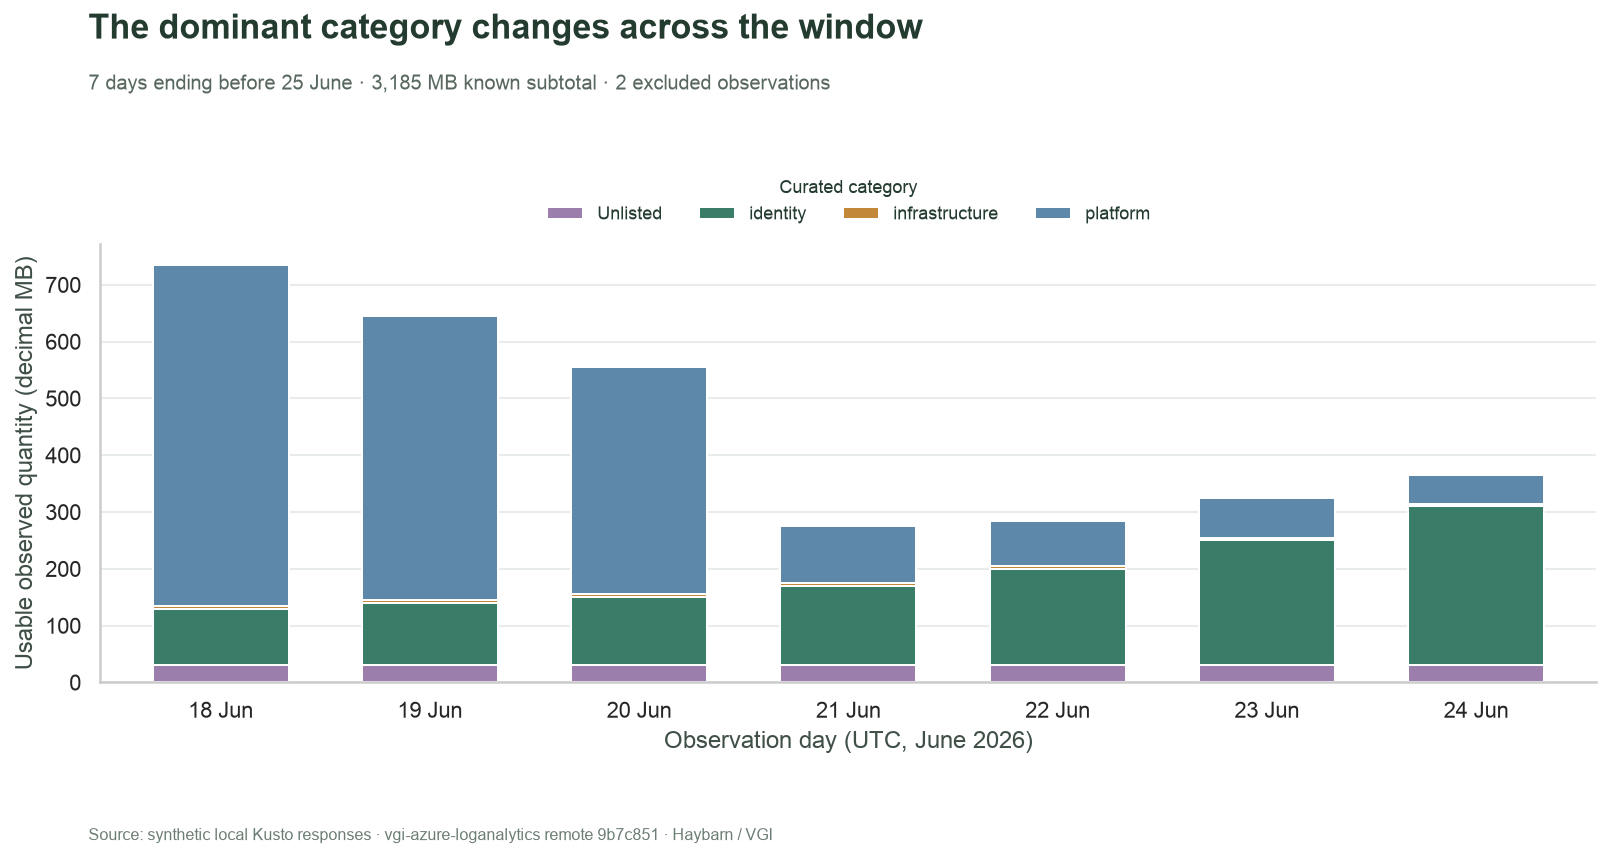

In [13]:
palette = {"identity": "#397D68", "platform": "#5D88A9", "infrastructure": "#C38738", "Unlisted": "#9C7EAC"}
wide = daily.pivot(index="day", columns="category", values="known_mb")
assert wide.notna().all().all(), "A missing category-day must not be silently plotted as zero"
fig, ax = plt.subplots(figsize=(11.5, 6))
wide.plot.bar(stacked=True, ax=ax, color=[palette[c] for c in wide.columns], width=0.65)
ax.set_xticklabels([d.strftime("%d Jun") for d in wide.index], rotation=0)
ax.set_xlabel("Observation day (UTC, June 2026)")
ax.set_ylabel("Usable observed quantity (decimal MB)")
ax.grid(axis="x", visible=False)
ax.legend(
    title="Curated category",
    ncol=4,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    fontsize=9,
    title_fontsize=9,
)
leaders = wide.idxmax(axis=1).unique()
pattern_title = (
    "The dominant category changes across the window"
    if len(leaders) > 1
    else f"{leaders[0].capitalize()} leads each observed day"
)
chart(
    fig,
    pattern_title,
    f"{WINDOW_DAYS} days ending before 25 June · {s.known_mb:,.0f} MB known subtotal · "
    f"{int(s.excluded_rows)} excluded observations",
)

## Rank known table subtotals, preserving the coverage caveat

Rank only tables with usable quantities; measured zero remains in the chart.
Tables without a usable observation stay in the coverage table above and are
omitted from the size comparison. The largest known subtotal is a ranking of
these measurements, not evidence about unavailable quantities.

In [14]:
%%sql ranking <<
SELECT table_name, category, known_mb, excluded_rows,
       100.0 * known_mb / nullif(sum(known_mb) OVER (),0) AS share_known_pct
FROM table_coverage WHERE usable_rows > 0 ORDER BY known_mb DESC, table_name;

In [15]:
leader = ranking.iloc[0]
prose(
    f"**{leader.table_name}** has the largest known subtotal: **{leader.known_mb:,.0f} MB**, "
    f"or **{leader.share_known_pct:.2f}%** of usable quantities in this window. "
    f"That table also has **{int(leader.excluded_rows)} excluded observation(s)**, "
    "so the coverage columns remain part of the interpretation."
)

**AzureDiagnostics** has the largest known subtotal: **1,800 MB**, or **56.51%** of usable quantities in this window. That table also has **1 excluded observation(s)**, so the coverage columns remain part of the interpretation.

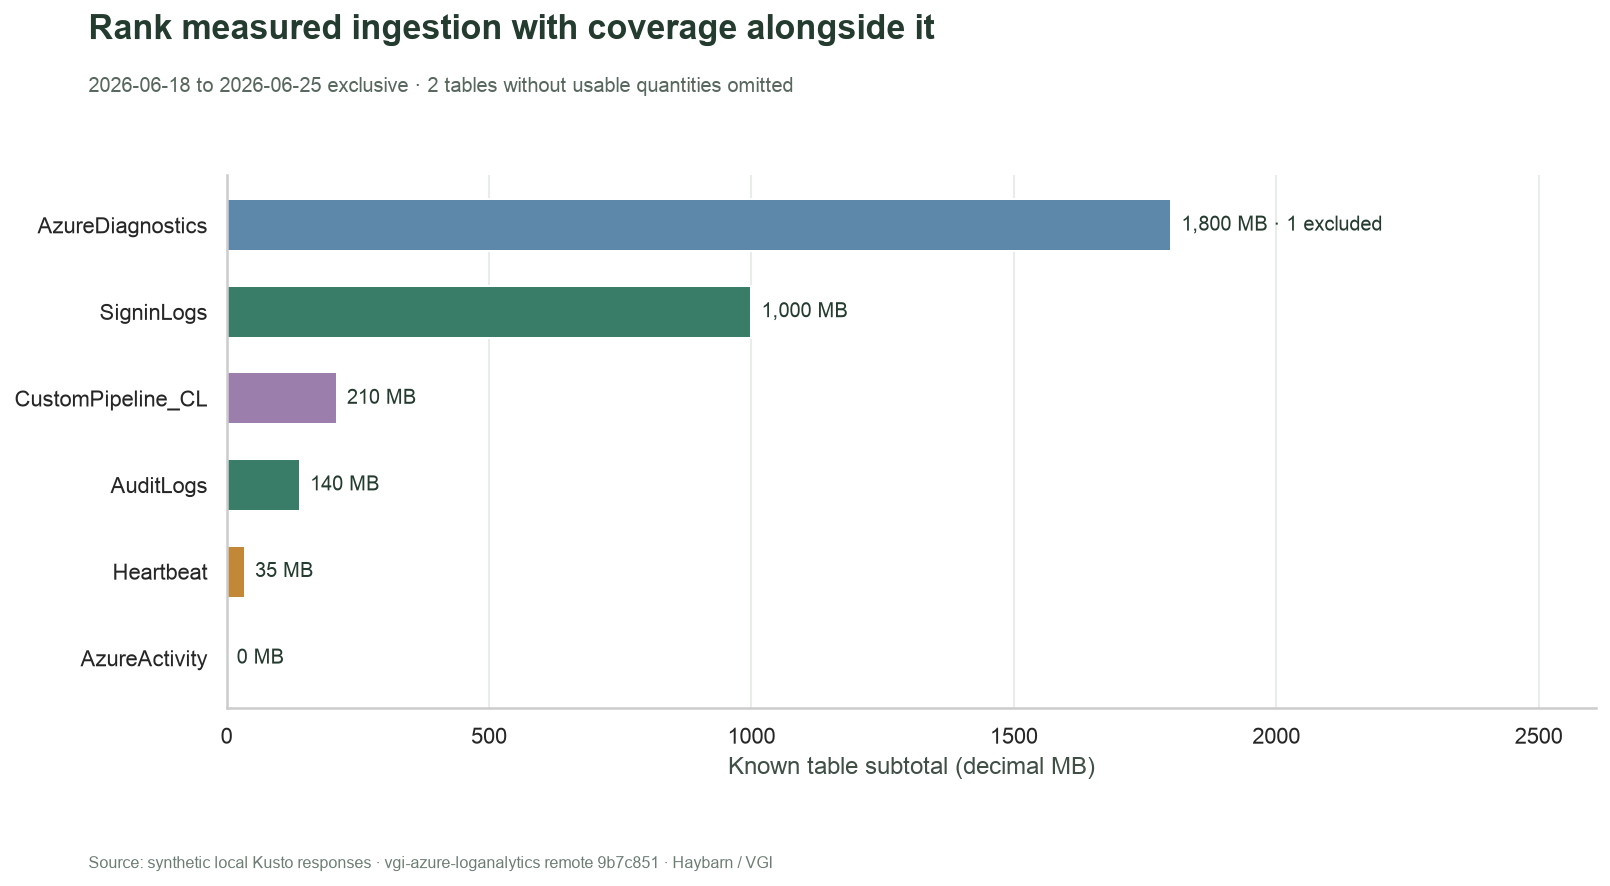

In [16]:
fig, ax = plt.subplots(figsize=(11.5, 6.2))
bars = ax.barh(ranking.table_name, ranking.known_mb, color=[palette[c] for c in ranking.category], height=0.6)
ax.bar_label(
    bars,
    labels=[
        f"{v:,.0f} MB" + (f" · {int(e)} excluded" if e else "")
        for v, e in zip(ranking.known_mb, ranking.excluded_rows, strict=True)
    ],
    padding=5,
    fontsize=10,
)
ax.invert_yaxis()
ax.set_xlim(0, max(float(ranking.known_mb.max()), 1) * 1.45)
ax.set_xlabel("Known table subtotal (decimal MB)")
ax.grid(axis="y", visible=False)
chart(
    fig,
    "Rank measured ingestion with coverage alongside it",
    f"{start_iso[:10]} to {end_iso[:10]} exclusive · "
    f"{int(s.absent_tables + s.unmeasured_tables)} tables without usable quantities omitted",
)

## Check the decoding, units and reconciliation

Check that snapshot rows contain no cursor, timestamps lie inside the chosen
window, the union preserves all indexed and observed table names, and daily/table
subtotals reconcile to usable quantities. NULL subtotals must remain NULL when no
usable measurements exist. Float64 sums use an absolute **10⁻⁹ MB** tolerance.

In [17]:
%%sql checks <<
SELECT 'snapshot has no cursor or marker' AS check_name,
       bool_and(_row_kind IS NULL AND _watermark_next IS NULL) AS passed FROM raw_usage
UNION ALL SELECT 'JSON decoding preserves one row per result',
       (SELECT count(*) FROM raw_usage) = (SELECT count(*) FROM typed_usage)
UNION ALL SELECT 'timestamps inside half-open UTC window', bool_and(
       observed_at >= TIMESTAMPTZ '{{start_iso}}' AND observed_at < TIMESTAMPTZ '{{end_iso}}') FROM typed_usage
UNION ALL SELECT 'coverage retains exactly the name union', NOT EXISTS (
       (SELECT table_name FROM table_coverage EXCEPT
        (SELECT table_name FROM table_index UNION SELECT table_name FROM typed_usage))
       UNION ALL
       ((SELECT table_name FROM table_index UNION SELECT table_name FROM typed_usage)
        EXCEPT SELECT table_name FROM table_coverage))
UNION ALL SELECT 'table totals reconcile to usable quantities', abs(
       (SELECT sum(known_mb) FROM table_coverage) -
       (SELECT sum(quantity_mb) FROM typed_usage WHERE measurement_status = 'usable')) < 1e-9
UNION ALL SELECT 'unmeasured subtotals stay NULL', bool_and(known_mb IS NULL)
       FROM table_coverage WHERE usable_rows = 0
UNION ALL SELECT 'usable and excluded partition observations', bool_and(
       observed_rows = usable_rows + excluded_rows) FROM table_coverage;

In [18]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), "A coverage relationship failed"
assert abs(daily.known_mb.sum() - s.known_mb) < 1e-9
assert len(fixture.requests) == 1, "The materialized API query must execute once"
request = fixture.requests[0]
assert request["query"] == QUERY and request["timespan"] == timespan
assert request["returned_rows"] == int(s.raw_rows)
prose(
    f"**All {len(checks)} SQL relationships passed.** Daily and table sums reconcile. "
    "The worker made **one local query POST**, preserving the visible KQL and timespan exactly, "
    "and emitted one JSON result per synthetic Kusto row."
)

,check_name,passed
0,snapshot has no cursor or marker,True
1,JSON decoding preserves one row per result,True
2,timestamps inside half-open UTC window,True
3,coverage retains exactly the name union,True
4,table totals reconcile to usable quantities,True
5,unmeasured subtotals stay NULL,True
6,usable and excluded partition observations,True


**All 7 SQL relationships passed.** Daily and table sums reconcile. The worker made **one local query POST**, preserving the visible KQL and timespan exactly, and emitted one JSON result per synthetic Kusto row.

## Experiment: shorten the observation window

Change **`WINDOW_DAYS = 7` to `WINDOW_DAYS = 3`**, restart, and run all. Predict that
removing the earlier platform spike will change the leading table. Compare the
largest known subtotal and its share, then verify that the shorter UTC window is
shown on both figures. Axes rescale with the window; compare labelled values
rather than bar widths between runs. Recheck exclusions: a shorter window changes which records
are observed, not the validity of their units.

This comparison describes these fixed synthetic observations. It is not a forecast,
a billing recommendation or evidence that absent tables stopped collecting data.
Restore **7** for the default. The [guide](README.md) gives a separate experiment
command that preserves the successful default outputs.

In [19]:
con.close()
cleanup(fixture, previous_url)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)